# Collinearity, Conditioning, and Ridge Regularization

We study
$$
$$
with two nearly collinear predictors.

OLS:
$$
\hat\beta_{\rm OLS}=(X^\top X)^{-1}X^\top y.
$$

Ridge:
$$
\boxed{
J_\lambda(\beta)=\|y-X\beta\|_2^2+\lambda\|\beta\|_2^2
}
$$
with solution
$$
\boxed{
\hat\beta_\lambda=(X^\top X+\lambda I)^{-1}X^\top y.
}
$$

The notebook shows:
- why $X^\top X$ becomes ill-conditioned,
- the long flat contour valley of the OLS objective,
- coefficient instability under tiny perturbations,
- how ridge changes the contours,
- how conditioning improves as \(\lambda\) increases,
- the bias/stability trade-off.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(12)

n = 100
x1 = rng.normal(0,1,n)
x2 = x1 + 0.02*rng.normal(0,1,n)

x1 -= x1.mean()
x2 -= x2.mean()

X = np.column_stack([x1,x2])
beta_true = np.array([2.0,2.0])

y = X @ beta_true + rng.normal(0,0.5,n)
y -= y.mean()

XtX = X.T @ X
Xty = X.T @ y

print("corr(X1,X2) =", np.corrcoef(x1,x2)[0,1])

corr(X1,X2) = 0.9997740356101276


## 1. Nearly collinear predictors

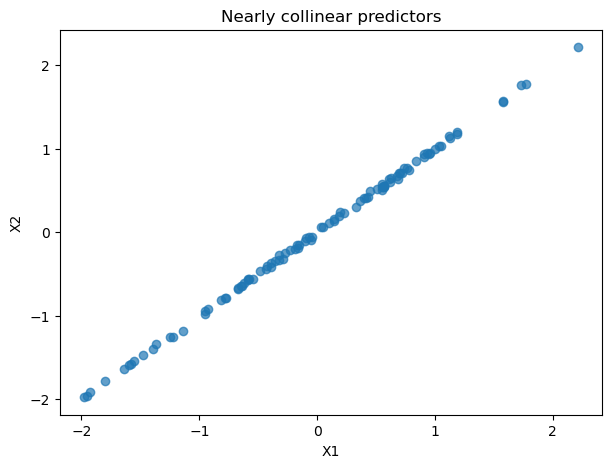

In [3]:
plt.figure(figsize=(7,5))
plt.scatter(x1,x2,alpha=0.7)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Nearly collinear predictors")
plt.show()

If $X_2\approx X_1$, then many combinations of $\beta_1,\beta_2$ give almost the same
$$
\beta_1X_1+\beta_2X_2.
$$
That is the source of instability.

## 2. Conditioning of \(X^T X\)

In [4]:
eigvals = np.linalg.eigvalsh(XtX)
print("X^T X =")
print(XtX)
print("\nEigenvalues =", eigvals)
print("Condition number =", np.linalg.cond(XtX))

X^T X =
[[83.21634832 83.09551627]
 [83.09551627 83.01237112]]

Eigenvalues = [1.87808573e-02 1.66209939e+02]
Condition number = 8849.965468329245


For symmetric positive definite $X^\top X$,
$$
\kappa(X^\top X)=\frac{\lambda_{\max}}{\lambda_{\min}}.
$$
A tiny smallest eigenvalue means a very large condition number.

## 3. Explicit inversion and coefficient sensitivity

In [5]:
beta_inv = np.linalg.inv(XtX) @ Xty
beta_lstsq = np.linalg.lstsq(X,y,rcond=None)[0]

print("True beta       =", beta_true)
print("Using inverse   =", beta_inv)
print("Using lstsq     =", beta_lstsq)

True beta       = [2. 2.]
Using inverse   = [1.71356886 2.27618842]
Using lstsq     = [1.71356886 2.27618842]


In practice, avoid explicitly forming \((X^\top X)^{-1}\); use `lstsq` or `solve`.
But the deeper issue is statistical: the problem itself is nearly non-identifiable.

In [6]:
y2 = y + rng.normal(0,0.05,n)

b1 = np.linalg.lstsq(X,y,rcond=None)[0]
b2 = np.linalg.lstsq(X,y2,rcond=None)[0]

print("beta from y          =", b1)
print("beta from perturbed y=", b2)
print("coefficient change   =", b2-b1)

pred1 = X @ b1
pred2 = X @ b2

print("RMS change in y =", np.sqrt(np.mean((y2-y)**2)))
print("RMS change in fitted predictions =", np.sqrt(np.mean((pred2-pred1)**2)))

beta from y          = [1.71356886 2.27618842]
beta from perturbed y= [1.83563752 2.16177675]
coefficient change   = [ 0.12206866 -0.11441167]
RMS change in y = 0.053750060202160735
RMS change in fitted predictions = 0.007472599652167157


This illustrates
\[
\boxed{\text{coefficients unstable, predictions comparatively stable}.}
\]

## 4. OLS cost contours

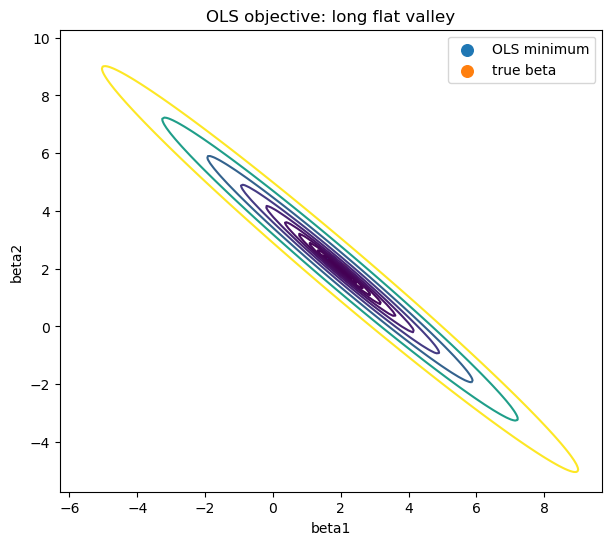

In [9]:
def J(beta1,beta2,lam=0):
    b = np.array([beta1,beta2])
    r = y - X@b
    return r@r + lam*(b@b)

beta_ols = np.linalg.lstsq(X,y,rcond=None)[0]

g1 = np.linspace(beta_ols[0]-8,beta_ols[0]+8,250)
g2 = np.linspace(beta_ols[1]-8,beta_ols[1]+8,250)
B1,B2 = np.meshgrid(g1,g2)

Z = np.empty_like(B1)
for i in range(B1.shape[0]):
    for j in range(B1.shape[1]):
        Z[i,j] = J(B1[i,j],B2[i,j],1)

levels = Z.min() + np.geomspace(0.05,100,14)

plt.figure(figsize=(7,6))
plt.contour(B1,B2,Z,levels=levels)
plt.scatter([beta_ols[0]],[beta_ols[1]],s=70,label="OLS minimum")
plt.scatter([beta_true[0]],[beta_true[1]],s=70,label="true beta")
plt.xlabel("beta1")
plt.ylabel("beta2")
plt.title("OLS objective: long flat valley")
plt.legend()
plt.show()

The long narrow valley is the geometry of collinearity: one parameter direction has very little curvature.

## 5. Ridge improves conditioning

In [14]:
lambdas = [0,0.01,0.1,1,10,100]
rows=[]

for lam in lambdas:
    A = XtX + lam*np.eye(2)
    if lam==0:
        b = np.linalg.lstsq(X,y,rcond=None)[0]
    else:
        b = np.linalg.solve(A,Xty)
    rows.append({
        "lambda":lam,
        "beta1":b[0],
        "beta2":b[1],
        "condition_number":np.linalg.cond(A),
        "||beta||":np.linalg.norm(b)
    })

ridge = pd.DataFrame(rows)
ridge

,lambda,beta1,beta2,condition_number,||beta||
0,0.00,1.713569,2.276188,8849.965468,2.849097
1,0.01,1.811556,2.177841,5775.364397,2.832795
2,0.10,1.950084,2.036982,1400.140918,2.819951
3,1.00,1.978787,1.986771,164.127484,2.804079
4,10.00,1.882130,1.880880,17.587962,2.660850
5,100.00,1.246119,1.244696,2.661600,1.761272


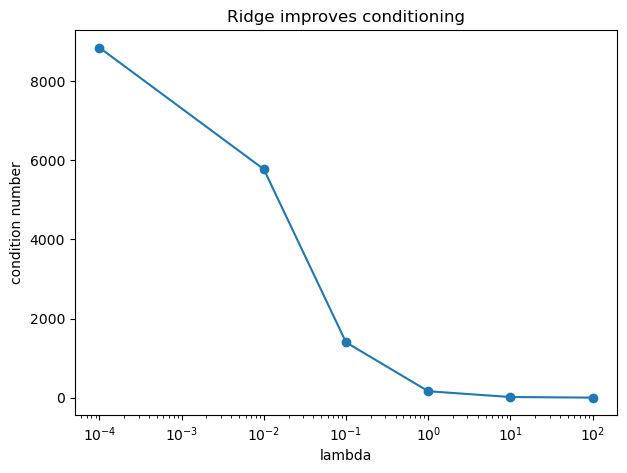

In [15]:
xplot = ridge["lambda"].replace(0,1e-4)

plt.figure(figsize=(7,5))
plt.semilogx(xplot,ridge["condition_number"],marker="o")
plt.xlabel("lambda")
plt.ylabel("condition number")
plt.title("Ridge improves conditioning")
plt.show()

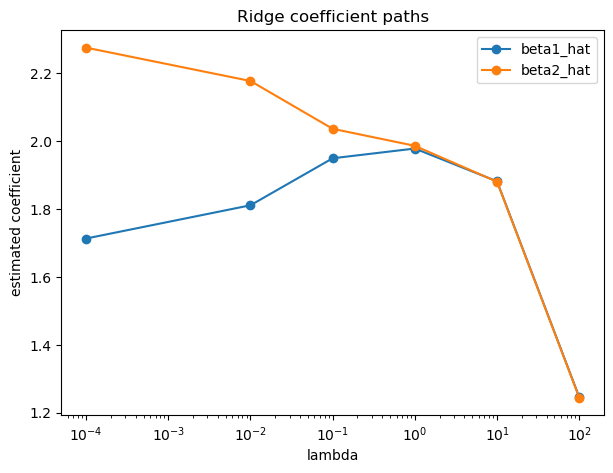

In [16]:
plt.figure(figsize=(7,5))
plt.semilogx(xplot,ridge["beta1"],marker="o",label="beta1_hat")
plt.semilogx(xplot,ridge["beta2"],marker="o",label="beta2_hat")
plt.xlabel("lambda")
plt.ylabel("estimated coefficient")
plt.title("Ridge coefficient paths")
plt.legend()
plt.show()

If \(d_i\) are eigenvalues of \(X^\top X\), ridge replaces them by
$$
d_i+\lambda.
$$
Hence
$$
\kappa(X^\top X+\lambda I)
=
\frac{d_{\max}+\lambda}{d_{\min}+\lambda}.
$$

## 6. Ridge contours for different regularization strengths

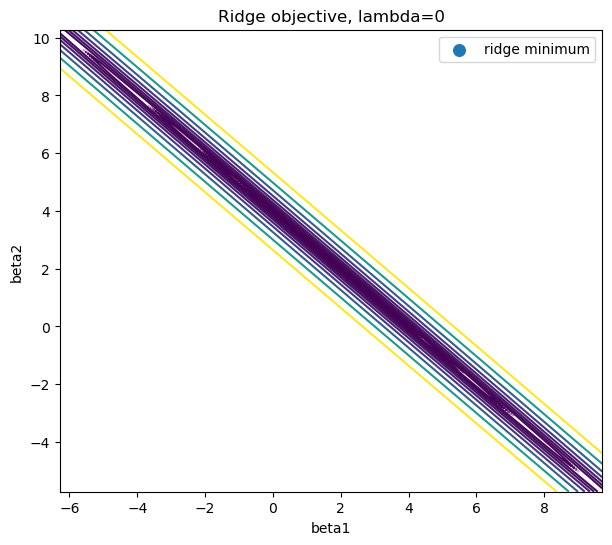

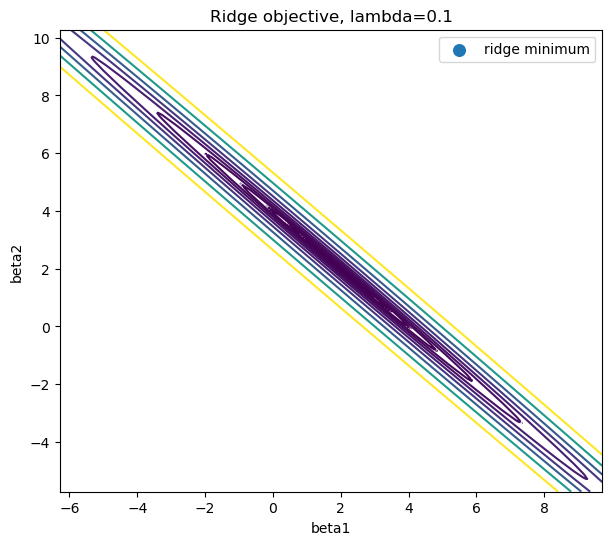

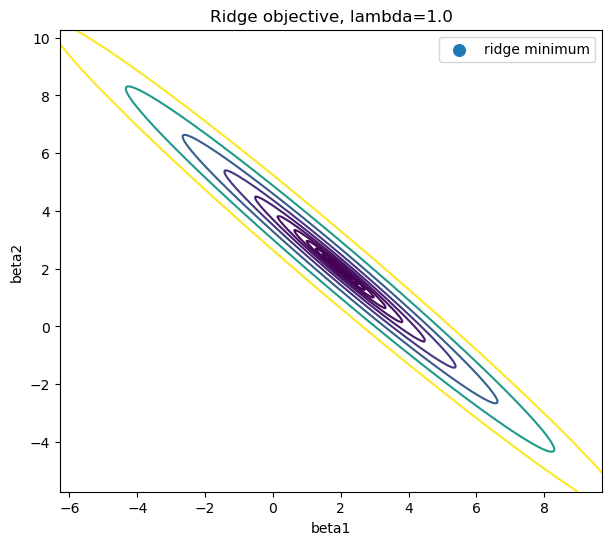

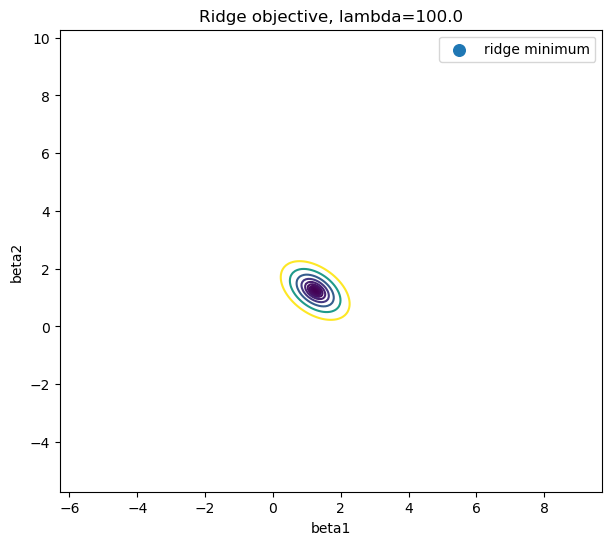

In [10]:
for lam in [0,0.1,1.0,100.0]:
    b = np.linalg.solve(XtX + lam*np.eye(2),Xty)

    Z = np.empty_like(B1)
    for i in range(B1.shape[0]):
        for j in range(B1.shape[1]):
            Z[i,j] = J(B1[i,j],B2[i,j],lam)

    levels = Z.min() + np.geomspace(0.05,150,14)

    plt.figure(figsize=(7,6))
    plt.contour(B1,B2,Z,levels=levels)
    plt.scatter([b[0]],[b[1]],s=70,label="ridge minimum")
    plt.xlabel("beta1")
    plt.ylabel("beta2")
    plt.title(f"Ridge objective, lambda={lam}")
    plt.legend()
    plt.show()

As \(\lambda\) increases:
- the flat direction gains curvature,
- contours become less elongated,
- the minimum moves toward the origin.

So ridge improves stability but introduces shrinkage bias.

## 7. Direct stability experiment

In [18]:
records=[]
for lam in [0,0.1,1,10]:
    bs=[]
    for _ in range(300):
        yp = y + rng.normal(0,0.05,n)
        if lam==0:
            b=np.linalg.lstsq(X,yp,rcond=None)[0]
        else:
            b=np.linalg.solve(XtX+lam*np.eye(2),X.T@yp)
        bs.append(b)
    bs=np.array(bs)
    records.append({
        "lambda":lam,
        "SD(beta1_hat)":bs[:,0].std(),
        "SD(beta2_hat)":bs[:,1].std(),
        "mean(beta1_hat)":bs[:,0].mean(),
        "mean(beta2_hat)":bs[:,1].mean()
    })

stab=pd.DataFrame(records)
stab

,lambda,SD(beta1_hat),SD(beta2_hat),mean(beta1_hat),mean(beta2_hat)
0,0.0,0.251296,0.251358,1.716441,2.273126
1,0.1,0.037706,0.037910,1.951598,2.035444
2,1.0,0.005766,0.005618,1.978779,1.986553
3,10.0,0.002580,0.002446,1.882226,1.881013


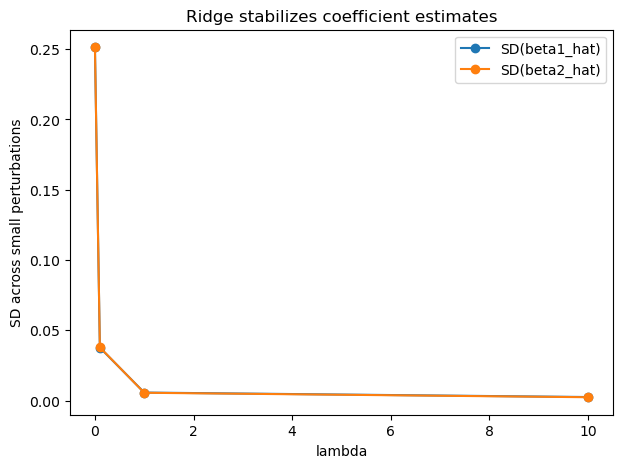

In [19]:
plt.figure(figsize=(7,5))
plt.plot(stab["lambda"],stab["SD(beta1_hat)"],marker="o",label="SD(beta1_hat)")
plt.plot(stab["lambda"],stab["SD(beta2_hat)"],marker="o",label="SD(beta2_hat)")
plt.xlabel("lambda")
plt.ylabel("SD across small perturbations")
plt.title("Ridge stabilizes coefficient estimates")
plt.legend()
plt.show()

## 8. Perfect collinearity

In [20]:
Xperfect=np.column_stack([x1,x1])
A0=Xperfect.T@Xperfect

print("rank(X) =", np.linalg.matrix_rank(Xperfect))
print("number of columns =", Xperfect.shape[1])
print("condition number of X^T X =", np.linalg.cond(A0))

try:
    np.linalg.inv(A0)
    print("Inverse computed")
except np.linalg.LinAlgError:
    print("X^T X is singular: inverse does not exist.")

for lam in [0.01,0.1,1,10]:
    A=A0+lam*np.eye(2)
    print(f"lambda={lam}: condition number={np.linalg.cond(A):.3f}")

rank(X) = 1
number of columns = 2
condition number of X^T X = inf
X^T X is singular: inverse does not exist.
lambda=0.01: condition number=16644.270
lambda=0.1: condition number=1665.327
lambda=1: condition number=167.433
lambda=10: condition number=17.643


# Take-home message

\[
\boxed{
\text{collinearity}
\Rightarrow
X^\top X\text{ nearly singular}
\Rightarrow
\text{flat cost direction}
\Rightarrow
\text{unstable coefficients}.
}
\]

Ridge adds curvature:
\[
\boxed{
J_\lambda(\beta)=\|y-X\beta\|^2+\lambda\|\beta\|^2
}
\]
and improves conditioning:
\[
\boxed{
X^\top X\to X^\top X+\lambda I.
}
\]

But larger \(\lambda\) also shrinks coefficients, so ridge is a bias-stability trade-off.